In [1]:
import sys
sys.path.append("..")

In [2]:
from functools import partial
from typing import Callable
import datetime

import numpy as np
from numpy import cos, cosh, exp
from numpy.typing import NDArray
import matplotlib.pyplot as plt

import mlflow
import pymc as pm
import pymc_marketing.mlflow
import pytensor  

from ml.models import BayesianInferenceModel
from ml.train import BayesianInferenceModelTrainer

/home/amanuelant/.local/lib/python3.10/site-packages/pymc_marketing/mlflow.py:185: FutureWarning: This functionality is experimental and subject to change. If you encounter any issues or have suggestions, please raise them at: https://github.com/pymc-labs/pymc-marketing/issues/new
  warnings.warn(warning_msg, FutureWarning, stacklevel=1)
/home/amanuelant/.local/lib/python3.10/site-packages/mlflow/pyfunc/utils/data_validation.py:186: UserWarning: Add type hints to the `predict` method to enable data validation and automatic signature inference during model logging. Check https://mlflow.org/docs/latest/model/python_model.html#type-hint-usage-in-pythonmodel for more details.
  color_warning(


In [3]:
# To avoid BLAS library not detected warning. See: https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
pytensor.config.blas__ldflags = '-llapack -lblas -lcblas' 

In [4]:
mlflow.set_tracking_uri("../mlruns")  # tell mlflow where mlruns dir is to track bayesian inference experiment

In [5]:
test_deltas = np.load(
    "../../test-trajectories/1D-delta/validation-deltas-1D-delta-nsets-10000.npy"
)
print(f"Test deltas shape: {test_deltas.shape}")
test_trajs = np.load(
    "../../test-trajectories/1D-delta/validation-trajectories-1D-delta-nsets-10000.npy"
)
print(f"Test trajectories shape: {test_trajs.shape}")

num_traj_to_test = 5
num_delta_to_test = 40

test_deltas = test_deltas[:num_delta_to_test]
test_trajs = test_trajs[:num_delta_to_test, :num_traj_to_test, :]

print(f"Truncated test deltas shape: {test_deltas.shape}")
print(f"Truncated test trajectories shape: {test_trajs.shape}")
print(f"Deltas: {test_deltas}")

Test deltas shape: (40,)
Test trajectories shape: (40, 10000, 48)
Truncated test deltas shape: (40,)
Truncated test trajectories shape: (40, 5, 48)
Deltas: [0.         0.05384615 0.10769231 0.16153846 0.21538462 0.26923077
 0.32307692 0.37692308 0.43076923 0.48461538 0.53846154 0.59230769
 0.64615385 0.7        0.75384615 0.80769231 0.86153846 0.91538462
 0.96923077 1.02307692 1.07692308 1.13076923 1.18461538 1.23846154
 1.29230769 1.34615385 1.4        1.45384615 1.50769231 1.56153846
 1.61538462 1.66923077 1.72307692 1.77692308 1.83076923 1.88461538
 1.93846154 1.99230769 2.04615385 2.1       ]


In [6]:
def wait_time_pdf(tau: float, omega: float, delta: float) -> float:
    """
    Calculates the waiting time distribution of a coherently
    driven two-level system based on omega and delta. Code adapted from:

    We set \gamma = 1 as in the paper.

    Args:
        tau: Time delay.
        omega: Rabi frequency.
        delta: Qubit-drive detuning.

    Returns:
        float: Probability density, w(tau).
    """

    R = np.sqrt((1 + 4 * (delta**2 + 4 * omega**2)) ** 2 - 64 * omega**2)
    w_tau = 8 * exp(-tau / 2) * omega**2 / R

    A = np.sqrt(-64 * omega**2 + (1 + 4 * delta**2 + 16 * omega**2) ** 2)
    sum_term1 = -cos(
        tau * np.sqrt(-1 + 4 * delta**2 + 16 * omega**2 + A) / (2 * np.sqrt(2))
    )
    sum_term2 = cosh(
        tau * np.sqrt(1 - 4 * delta**2 - 16 * omega**2 + A) / (2 * np.sqrt(2))
    )

    w_tau *= sum_term1 + sum_term2

    return w_tau


def logp_fn(value: float, delta: float, omega: float) -> float:
    """
    Logarithm of the waiting time distribution for a given value of tau, delta, and omega.
    Used as a custom distribution in PyMC.
    Args:
        value: Time delay (tau).
        delta: Detuning frequency.
        omega: Rabi frequency.
    Returns:
        float: Logarithm of the waiting time probability density.
    """

    w = wait_time_pdf(value, omega, delta)

    # Add small epsilon to avoid log(0)
    return np.log(w + 1e-12)

In [ ]:
def build_1D_model(trajectory: NDArray[np.float64], logp_fn: Callable) -> BayesianInferenceModel:
    with pm.Model() as model:
        # define uniform priors on parameters. See Appendix E of the paper
        delta = pm.Uniform("delta", 0, 2.1)

        # define likelihood (waiting-time distribution)
        pm.CustomDist(
            "likelihood", delta, logp=logp_fn, observed=trajectory
        )

    return BayesianInferenceModel(model=model)


def build_2D_model(trajectory: NDArray[np.float64], logp_fn: Callable) -> BayesianInferenceModel:
    with pm.Model() as model:
        # define uniform priors on parameters. See Appendix E of the paper
        delta = pm.Uniform("delta", 0, 2.1)
        omega = pm.Uniform("omega", 0.25, 2.1)

        # define likelihood (waiting-time distribution)
        pm.CustomDist(
            "likelihood", delta, omega, logp=logp_fn, observed=trajectory
        )

    return BayesianInferenceModel(model=model)

In [8]:
pymc_marketing.mlflow.autolog(
    log_metadata_info=False, arviz_summary_kwargs={"hdi_prob": 0.95}
)  # don't log info about data used

current_datetime = datetime.datetime.now()
mlflow.set_experiment("Bayesian Inference")

with mlflow.start_run() as grand_parent_run:
    for i, (true_delta, trajectories) in enumerate(zip(test_deltas, test_trajs)):
        with mlflow.start_run(run_name=f"Delta {i+1}", nested=True) as parent_run:
            parent_run_id = parent_run.info.run_id
            mlflow.log_metric("true_delta", true_delta)

            for j, trajectory in enumerate(trajectories):
                model = build_1D_model(trajectory=trajectory, logp_fn=partial(logp_fn, omega=1))
                trainer = BayesianInferenceModelTrainer()

                with mlflow.start_run(run_name=f"Trajectory {j+1}", nested=True):
                    mlflow.log_metric("true_delta", true_delta)

                    trainer.train(
                        model=model,
                        draws=20_000,
                        cores=5,
                        chains=5,
                        tune=1_500,  # increase tune to reduce divergences
                        target_accept=0.98,  # increased target_accept to reduce divergences
                        nuts_sampler="nutpie",  # "blackjax" or "numpyro" can also be used
                        progressbar=False,
                    )
                

            # compute summary statistics for child runs
            child_runs = mlflow.search_runs(
                filter_string=f"tags.mlflow.parentRunId = '{parent_run_id}'",
                output_format="pandas",
            )

            mlflow.log_metric("num_runs", len(child_runs))
            mlflow.log_metric(
                "total_divergences", child_runs["metrics.total_divergences"].sum()
            )
            
            for var_name in model.free_rvs:
                mlflow.log_metric(
                    f"mean_estimate_{var_name}",
                    child_runs[f"metrics.{var_name}_mean"].mean(),
                )

                errors = child_runs[f"metrics.{var_name}_mean"] - true_delta
                rmse = np.sqrt(np.mean(errors**2))
                mlflow.log_metric(f"{var_name}_rmse", rmse, step=i)
                mlflow.log_metric(f"{var_name}_bias", errors.mean(), step=i)
    
mlflow.end_run()


2025/07/31 15:57:46 INFO mlflow.tracking.fluent: Experiment with name 'Bayesian Inference' does not exist. Creating a new experiment.


arviz - WARNING - Array contains NaN-value.
arviz - WARNING - Array contains NaN-value.


MlflowException: The run ddb7aa22b82a4cb69d84022503b81746 must be in 'active' lifecycle_stage.

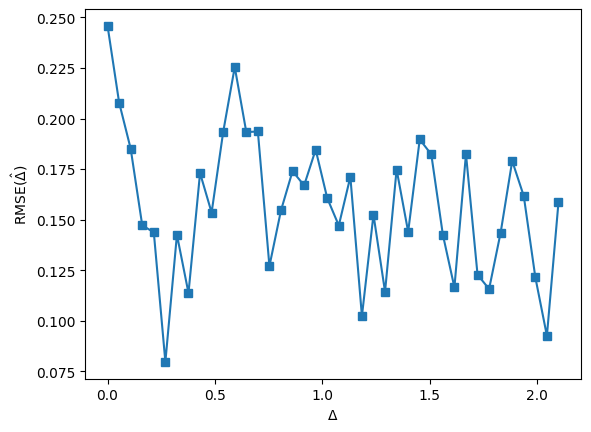

In [ ]:
experiment = mlflow.get_experiment_by_name("Bayesian Inference")
exp_id = experiment.experiment_id
runs = mlflow.search_runs(experiment_ids=[exp_id])
# for some reason some runs have NaN values for metrics, so we filter them out
runs = runs[runs["metrics.true_delta"].notna() & runs["metrics.delta_rmse"].notna()]

plt.plot(runs["metrics.true_delta"], runs["metrics.delta_rmse"], marker='s')
# plt.ylim(0.1, 0.35)
plt.xlabel(r"$\Delta$")
plt.ylabel(r"RMSE($\hat{\Delta}$)");

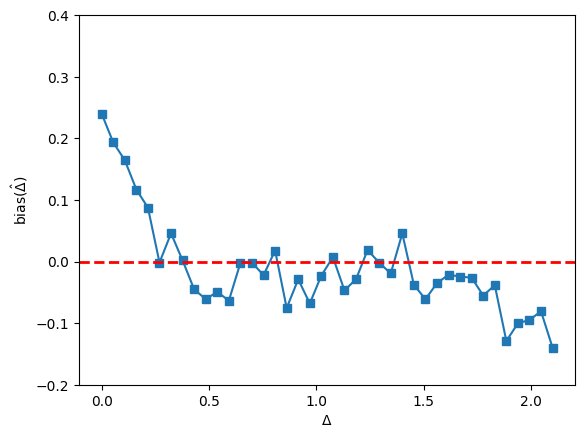

In [ ]:
plt.plot(runs["metrics.true_delta"], runs["metrics.delta_bias"], marker='s', linestyle='-')
plt.axhline(y=0, color='red', linestyle='--', linewidth=2)  # horizontal line at bias = 0
plt.ylim(-0.2, 0.4)
plt.xlabel(r"$\Delta$")
plt.ylabel(r"bias($\hat{\Delta}$)");

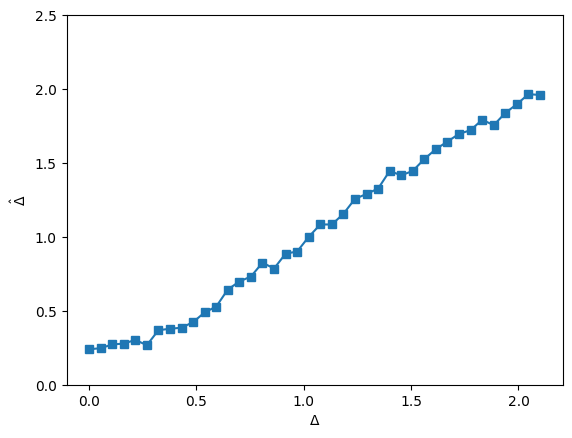

In [ ]:
plt.plot(runs["metrics.true_delta"], runs["metrics.mean_estimate_delta"], marker='s', linestyle='-')

plt.ylim(0, 2.5)
plt.xlabel(r"$\Delta$")
plt.ylabel(r"$\hat{\Delta}$");

In [ ]:
print(mlflow.active_run())
mlflow.end_run()

None
